# Linear Regression from Scratch — California Housing

A from-scratch NumPy implementation of Linear Regression (batch gradient descent and the closed-form normal equation), benchmarked on the California Housing dataset.


In [45]:
from linear_regression import LinearRegression

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

from linear_regression import LinearRegression 

## 1. Dataset

In [47]:
california = fetch_california_housing()

In [48]:
X = california.data
y = california.target
df = pd.DataFrame(X, columns=california.feature_names)
df["Price"] = y

print("X shape:", X.shape)
print("y shape:", y.shape)
print(california.feature_names)
print(df.head())

X shape: (20640, 8)
y shape: (20640,)
['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  


In [49]:
print(df.info())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   MedInc      20640 non-null  float64
 1   HouseAge    20640 non-null  float64
 2   AveRooms    20640 non-null  float64
 3   AveBedrms   20640 non-null  float64
 4   Population  20640 non-null  float64
 5   AveOccup    20640 non-null  float64
 6   Latitude    20640 non-null  float64
 7   Longitude   20640 non-null  float64
 8   Price       20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB
None
             MedInc      HouseAge      AveRooms     AveBedrms    Population  \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean       3.870671     28.639486      5.429000      1.096675   1425.476744   
std        1.899822     12.585558      2.474173      0.473911   1132.462122   
min        0.499900      1.000000      0.846154      0.333333      3.000000   
2

## 2. Exploratory Data Analysis

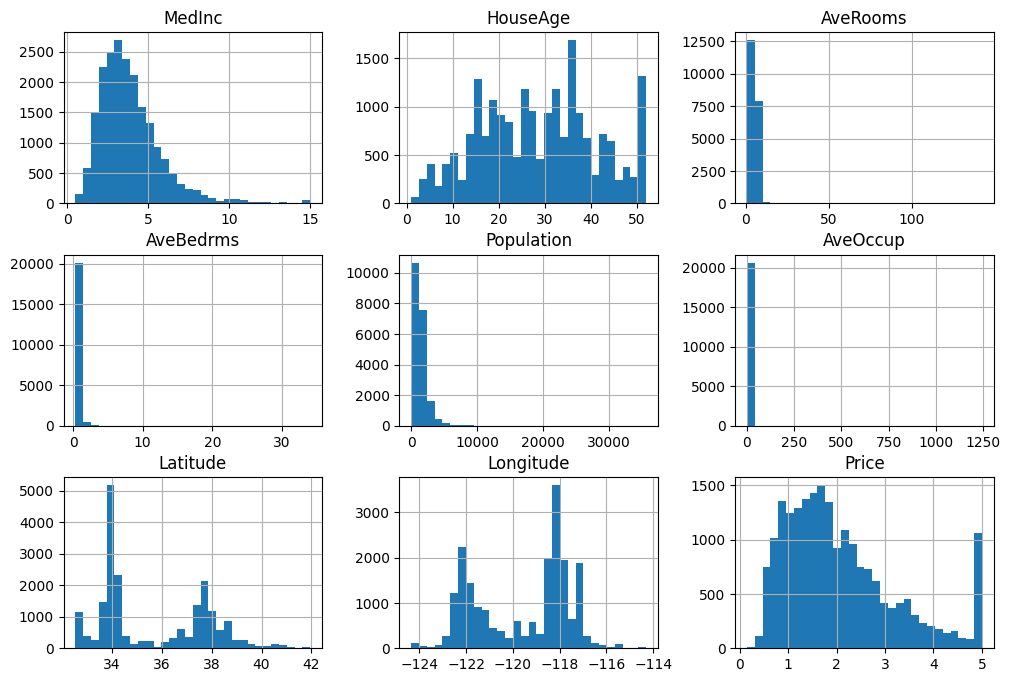

In [50]:
df.hist(figsize=(12, 8), bins=30)
plt.show()

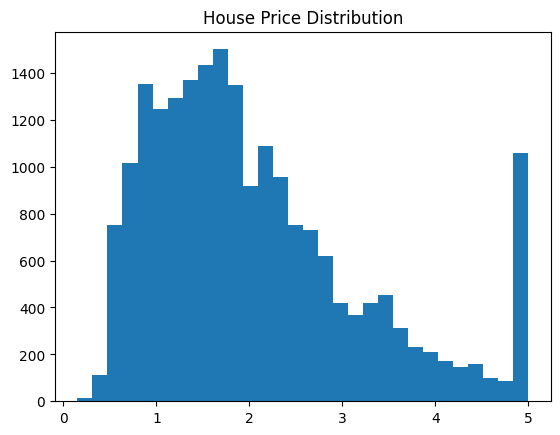

In [51]:
plt.hist(y, bins=30)
plt.title("House Price Distribution")
plt.show()

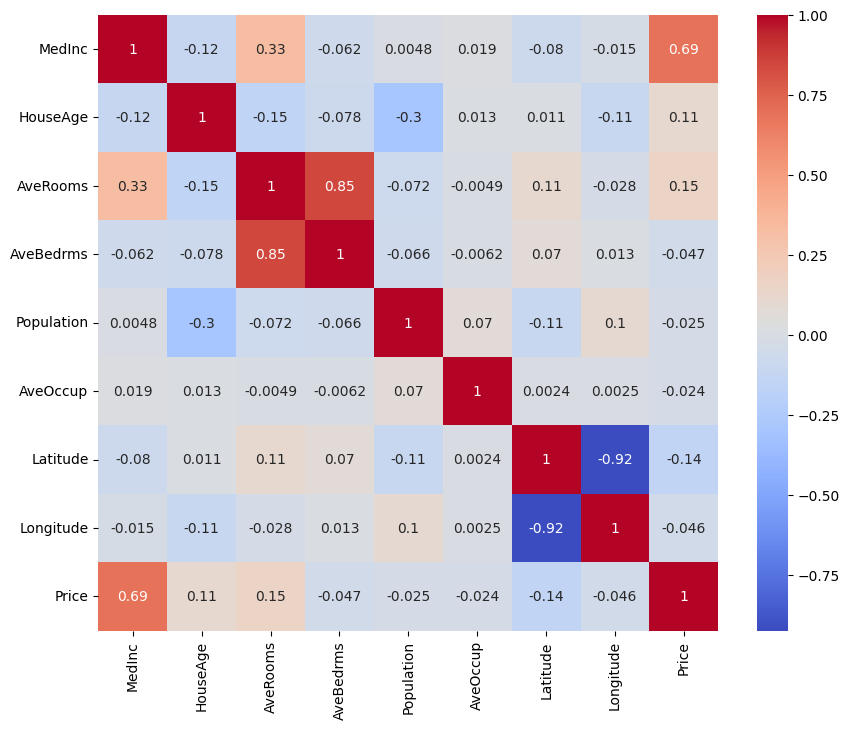

In [52]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

## 3. Train / Test Split

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [54]:
print("Training data size:", X_train.shape)
print("Testing data size:", X_test.shape)

Training data size: (16512, 8)
Testing data size: (4128, 8)


## 4. Feature Scaling

In [55]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [56]:
print(X_train_scaled.mean(axis=0))
print(X_train_scaled.std(axis=0))

[-6.59266865e-15 -6.68608149e-17  8.01559239e-15 -1.17273358e-15
 -2.60880895e-18 -1.13675656e-16  7.99652724e-14 -3.87910056e-13]
[1. 1. 1. 1. 1. 1. 1. 1.]


## 5. Training

In [57]:
model_gd = LinearRegression(method='gradient_descent')
model_gd.fit(X_train_scaled, y_train, epochs=1000, learning_rate=0.01)

Epoch 0, Loss = 5.629742323103131
Epoch 100, Loss = 0.7103658676026788
Epoch 200, Loss = 0.5953130085792435
Epoch 300, Loss = 0.5732304657671403
Epoch 400, Loss = 0.5584093310450804
Epoch 500, Loss = 0.5476601015303806
Epoch 600, Loss = 0.5398283477804547
Epoch 700, Loss = 0.5341100200814504
Epoch 800, Loss = 0.5299255181901082
Epoch 900, Loss = 0.5268559059337551


In [58]:
model_ne = LinearRegression(method='normal_equation')
model_ne.fit(X_train_scaled, y_train)

In [59]:
print("GD Weights:", model_gd.weights)
print("NE Weights:", model_ne.weights)

print(model_gd.bias)
print(model_ne.bias)

GD Weights: [ 0.8580605   0.1501549  -0.25253771  0.28100715  0.00710958 -0.04344213
 -0.68321834 -0.65415242]
NE Weights: [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291
 -0.89692888 -0.86984178]
2.0719469338916703
2.071946937378618


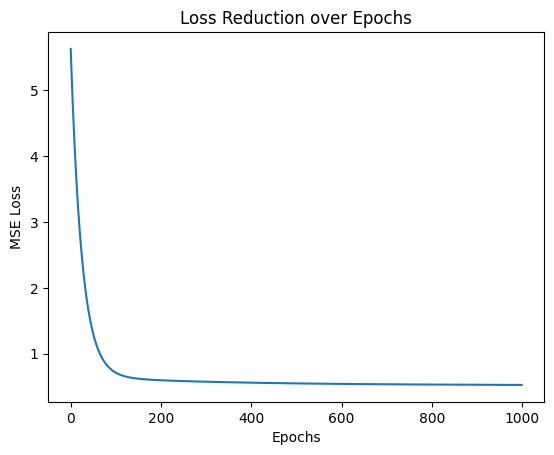

In [65]:
plt.plot(model_gd.loss_history)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Loss Reduction over Epochs')
plt.show()

### Comparing different learning rates

Epoch 0, Loss = 5.629742323103131
Epoch 100, Loss = 0.5244661096013542
Epoch 200, Loss = 0.518385559739066
Epoch 300, Loss = 0.5179821351136198
Epoch 400, Loss = 0.5179397909383054
Epoch 500, Loss = 0.5179340985855966
Epoch 600, Loss = 0.5179332701790051
Epoch 700, Loss = 0.5179331471235166
Epoch 800, Loss = 0.5179331287530536
Epoch 900, Loss = 0.5179331260073374


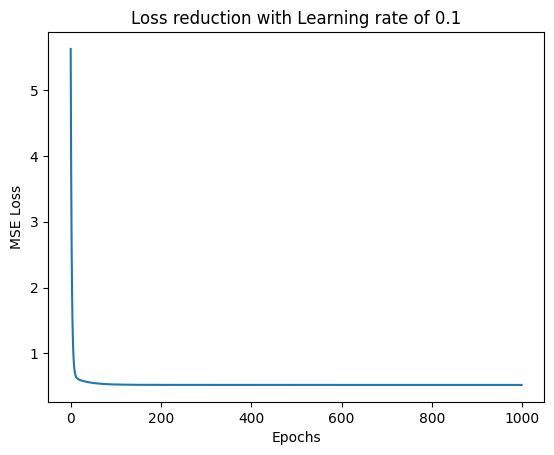

In [66]:
model_lr1 = LinearRegression(method="gradient_descent")

model_lr1.fit(
    X_train_scaled,
    y_train,
    epochs=1000,
    learning_rate=0.1
)

plt.plot(model_lr1.loss_history)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Loss reduction with Learning rate of 0.1')
plt.show()

In [ ]:
model_lr2 = LinearRegression(method="gradient_descent")

model_lr2.fit(
    X_train_scaled,
    y_train,
    epochs=1000,
    learning_rate=0.001
)

plt.plot(model_lr2.loss_history)
plt.xlabel('Epochs')
plt.ylabel('MSE Loss')
plt.title('Loss reduction with Learning rate of 0.001')
plt.show()


In [64]:
y_train_pred_ne = model_ne.predict(X_train_scaled)
y_test_pred_ne = model_ne.predict(X_test_scaled)

# 2. Compute R2 scores
r2_train_ne = r2_score(y_train, y_train_pred_ne)
r2_test_ne = r2_score(y_test, y_test_pred_ne)

print(f"Normal Equation - Train R² Score: {r2_train_ne:.4f}")
print(f"Normal Equation - Test R² Score: {r2_test_ne:.4f}")

Normal Equation - Train R² Score: 0.6126
Normal Equation - Test R² Score: 0.5758


In [67]:
print("--- LR of 0.01 ---")
y_pred = model_gd.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
print("MSE: ",mse)
r2 = r2_score(y_test, y_pred)
print("R²:",r2)

y_pred = model_gd.predict(X_train_scaled)
mse = mean_squared_error(y_train, y_pred)
print("MSE(train): ",mse)
r2 = r2_score(y_train, y_pred)
print("R²(train):",r2)

print("--- LR of 0.1 ---")
y_pred = model_lr1.predict(X_test_scaled)
mse = mean_squared_error(y_test, y_pred)
print("MSE: ",mse)
r2 = r2_score(y_test, y_pred)
print("R²:",r2)

y_pred = model_lr1.predict(X_train_scaled)
mse = mean_squared_error(y_train, y_pred)
print("MSE(train): ",mse)
r2 = r2_score(y_train, y_pred)
print("R²(train):",r2)

--- LR of 0.01 ---
MSE:  0.5545795065308549
R²: 0.5767889905063643
MSE(train):  0.5245980367816365
R²(train): 0.6075653895649575
--- LR of 0.1 ---
MSE:  0.5558926553314607
R²: 0.5757868996916564
MSE(train):  0.5179331255968365
R²(train): 0.6125511913427096


## Effect of the Learning Rate

Linear Regression was implemented manually using batch Gradient Descent, with Mean
Squared Error (MSE) as the loss function and gradients computed by hand. To study the
effect of the learning rate, the model was trained with three values — `0.001`, `0.01`,
and `0.1` — and the loss curves were compared.

**Learning Rate = 0.001** — Loss decreased from ~5.63 to ~0.76. The descent was very
stable, but convergence was slow: even after 1000 epochs the model had not reached the
optimum.

**Learning Rate = 0.01** — Fastest, most reliable convergence. Loss approached its final
value in roughly 100 epochs and then stayed essentially flat, ending around **0.518** —
the lowest of the three runs.

**Learning Rate = 0.1** — Also converged well, from 5.63 down to about 0.53, and reached
the optimum faster than the 0.01 run.

**Takeaway:** a learning rate that's too small leads to very slow convergence, while a
larger learning rate (0.1 here) reaches the optimum fastest without becoming unstable.
For this problem, 0.1 gave the best trade-off between speed and stability.


## Why `pinv` Instead of `inv`?

`np.linalg.inv` only works on matrices with a non-zero determinant (full-rank matrices).
If two features in the data are linearly related (e.g. one is a multiple of another) or
the number of features exceeds the number of samples, `Xᵀ X` becomes singular, `inv`
raises an error, and the program stops. `np.linalg.pinv` (the Moore–Penrose
pseudo-inverse), on the other hand, always returns a solution.

Even when a matrix isn't perfectly singular, its determinant can be very close to zero.
In that case `inv` produces severe floating-point instability, generating weights with
huge, meaningless magnitudes. `pinv`, typically computed via SVD, is far more robust to
this kind of near-singularity.

When `Xᵀ X` is not invertible, infinitely many solutions exist for the model weights.
`pinv` handles this gracefully by returning the *minimum-norm* solution (smallest L2
norm) among them — a desirable property for avoiding overfitting.


## Comparing the Two Models' Weights

```
GD Weights: [ 0.8580605   0.1501549  -0.25253771  0.28100715  0.00710958 -0.04344213 -0.68321834 -0.65415242]
NE Weights: [ 0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772 -0.0408291  -0.89692888 -0.86984178]
```

The weights aren't identical, but they're close across most features. The differences
come from Gradient Descent not fully converging within a limited number of epochs, plus
floating-point numerical error.

The bias terms from the two methods are nearly identical too — `2.0719469338916703` (GD)
vs. `2.0719469373786135` (NE), a difference on the order of a few billionths, which is
practically negligible. Both methods converge to essentially the same optimum.

An R² of **0.5768** means the model explains about 57.7% of the variance in house prices.
That's a reasonable result for a simple linear model, but it also shows a meaningful
share of the price variation is driven by factors this linear model doesn't capture.
